In [1]:
import torch
import torchvision
from torchvision.transforms import v2

import torch.nn as nn
import torch.nn.functional as F

import numpy as np
import matplotlib.pyplot as plt

In [2]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

cuda


I will use MNIST dataset. The MNIST dataset consists of 28×28 grayscale images of handwritten digits from 0 to 9.

In [3]:
transform = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize((0.5,), (0.5,))]) # Dataset with only one out_channel

bsize = 64

train = torchvision.datasets.MNIST(root='./data', train=True, download=True, transform=transform)
train_loader = torch.utils.data.DataLoader(train, batch_size=bsize, shuffle=True)

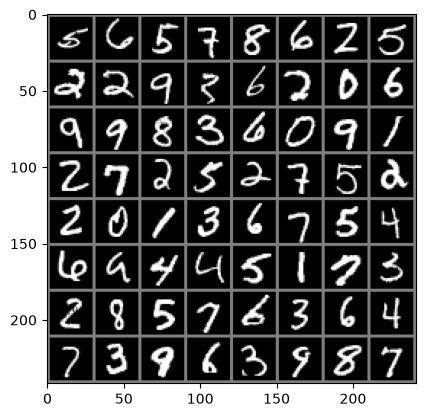

In [4]:
def imshow(img):
    img = img / 2 + 0.5     # unnormalize
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.show()


# get some random training images
dataiter = iter(train_loader)
images, _ = next(dataiter)

# show images
imshow(torchvision.utils.make_grid(images))

I will develop a Gaussian VAE, which means that the encoder and decoder will be distributed as it follows:

### Encoder
$$
q_\theta (z | x) \sim \mathcal N (z; \mu_\theta(x), \sigma^2_\theta(x))
$$

### Decoder
$$
p_\phi(x | z) \sim \mathcal N (x; \mu_\phi(z), \sigma^2 \mathbf I)
$$

To generate $\sigma^2_\theta(x)$ I will use the Cholesky decomposition. That means: I will generate a lower triangular matrix L, and compute sigma as: $\sigma^2_\theta(x) = L L^T$. For this purpose, the Encoder will return the lower triangular part, that is, a vector of $\frac{d(d+1)}{2}$ elements where $d$ is the dimension of the latent space.

In [5]:
class Encoder(nn.Module):
    def __init__(self, latent_dim = 16) -> None:
        super().__init__()
        self.lin1 = nn.Linear(28*28, 14*14)
        self.lin2 = nn.Linear(14*14, 7*7)
        self.mu = nn.Linear(7*7, latent_dim)
        self.L_matrix = nn.Linear(7*7, int(latent_dim*(latent_dim+1)/2)) # This layer will generate the lower triangular matrix of the Cholesky decomposition of sigma(z)

    def forward(self, x: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
        x = x.flatten(start_dim=1) # [bsize, 1, 28, 28] -> [bsize, 28*28]
        x = self.lin1(x) # [bsize, 28*28] -> [bsize, 14*14]
        x = F.relu(x)
        x = self.lin2(x) # [bsize, 14*14] -> [bsize, 7*7]
        x = F.relu(x)
        mu = self.mu(x) # [bsize, 7*7] -> [bsize, latent_dim]
        L_matrix = self.L_matrix(x) # [bsize, 7*7] -> [bsize, latent_dim*(latent_dim+1)/2)]
        return(mu, L_matrix)

class Decoder(nn.Module):
    def __init__(self, latent_dim = 16):
        super().__init__()
        self.lin1 = nn.Linear(latent_dim, 7*7)
        self.lin2 = nn.Linear(7*7, 14*14)
        self.mu = nn.Linear(14*14, 28*28)

    def forward(self, z: torch.Tensor) -> torch.Tensor:
        z = self.lin1(z) # [bsize, latent_dim] -> [bsize, 7*7]
        z = F.relu(z) 
        z = self.lin2(z) # [bsize, 7*7] -> [bsize, 14*14]
        z = F.relu(z)
        mu_z = self.mu(z) # [bsize, 14*14] -> [bsize, 28*28]
        return(mu_z)

In [6]:
class VAE(nn.Module):
    def __init__(self, latent_dim = 16, decoder_sigma=1):
        super().__init__()
        self.encoder = Encoder(latent_dim=latent_dim)
        self.decoder = Decoder(latent_dim=latent_dim)
        self.latent_dim = latent_dim
        self.decoder_sigma = decoder_sigma

    def build_cholesky_factor(self, m: torch.Tensor) -> torch.Tensor:
        # Now we create our covariance matrix using Cholesky decomposition
        tril_matrix = torch.zeros(m.shape[0], self.latent_dim, self.latent_dim, device=m.device) # [bsize, latent_dim, latent_dim]
        # Select indices from the lower triangular matrix
        low_indices = torch.tril_indices(self.latent_dim, self.latent_dim) # [bsize, latent_dim(latent_dim+1)/2]
        # It assign the values of sigma to the lower diag
        tril_matrix[:,low_indices[0], low_indices[1]] = m # [bsize, latent_dim, latent_dim]
        # The main diag has to be positive
        tril_matrix = tril_matrix.diagonal_scatter(torch.exp(tril_matrix.diagonal(dim1=1, dim2=2)), dim1=1, dim2=2) # [bsize, latent_dim, latent_dim]
        # Cholesky decomposition (It is not needed in this code)
        # Sigma_matrix = torch.matmul(tril_matrix, tril_matrix.mT) # [bsize, latent_dim, latent_dim]

        return(tril_matrix)
        
    def forward(self, x):
        mu, L_matrix = self.encoder(x)

        Cholesky_decomposition = self.build_cholesky_factor(L_matrix) # [bsize, latent_dim, latent_dim]
        eps = torch.randn_like(mu) # [bsize, latent_dim]
        z = mu + torch.bmm(Cholesky_decomposition, eps.unsqueeze(-1)).squeeze(-1) # eps need to be of shape [bsize, latent_dim, 1] in order to use batch matrix multiplication

        mu_z = self.decoder(z) # [bsize, 28*28]
        x_recon = mu_z + self.decoder_sigma*torch.randn_like(mu_z) # [bsize, 28*28]
        x_recon = x_recon.view(-1, 1, 28, 28) # [bsize, 1, 28, 28]

        return([x_recon, mu_z, mu, Cholesky_decomposition])


### ELBO error
$$
-\mathcal L_{ELBO} (\phi, \theta, x) = \frac{D}{2}\log(2\pi) + D\log(\sigma) + \frac{1}{2 \sigma^2}\mathbb E_{z\sim q_\theta(\bullet | x)} \left[ ||x-\mu_\phi(z)||^2 \right] + D_{KL}(q_\theta (z|x) || p_{prior}(z))
$$

In the case of a Gaussian autoencoder, the $D_{KL}$ term can be computed as:

$$
D_{KL}(q_\theta (z|x) || p_{prior}(z)) = \frac{1}{2} \Big( \text{Tr}(\sigma_\theta^2(x)) + \vert{}\vert{}\mu_\theta(x)\vert{}\vert{}^2 - d - \log \vert{}\sigma_\theta^2(x)\vert{} \Big)
$$
Where $d$ is the dimension of the latent space. We can easily compute $\text{Tr}(\sigma^2_\theta(x))$ and $\vert{}\sigma_\theta^2(x)\vert{}$ using its Cholesky decomposition, which is already calculated.
$$
\operatorname{Tr}(\sigma_\theta^2(x)) = \sum_{i} \sum_{k} L_{ik}^2 \quad\quad \log \vert{}\sigma_\theta^2(x)\vert{} = \log \left( \prod_{i} L_{ii}^2 \right) = 2\sum_i \log L_{ii}
$$

In [7]:
def L_elbo(x, mu_z, mu_x, Cholesky_matrix, decoder_sigma=1):
    x = x.flatten(start_dim=1)
    d = mu_x.shape[1]  # Latent space dimension per sample
    
    # Reconstruction error per sample (MSE sum across image pixels)
    recon_per_sample = 0.5 / (decoder_sigma**2) * F.mse_loss(x, mu_z, reduction="none").sum(dim=1)
    # recon_per_sample += 0.5 * x.shape[1] * np.log(2 * np.pi) + x.shape[1] * np.log(decoder_sigma)  # Constant w.r.t parameters
    
    # KL divergence per sample
    D_kl_per_sample = 0.5 * (
        torch.sum(Cholesky_matrix.pow(2), dim=(1, 2)) +
        torch.sum(mu_x.pow(2), dim=1) -
        d -
        2.0 * torch.sum(torch.log(Cholesky_matrix.diagonal(dim1=-2, dim2=-1)), dim=1)
    )
    
    # Return batch average of the negative ELBO
    return (recon_per_sample + D_kl_per_sample).mean()


In [8]:
import torch.optim as optim

model = VAE(decoder_sigma=1)
model = model.to(device)
optimizer = optim.Adam(model.parameters(), lr=1e-3) 
train_losses = []

In [9]:
train = True
if not train:
	model = VAE(decoder_sigma=1)
	model.load_state_dict(torch.load("./models/VAE", weights_only=True))
	model = model.to(device)

else:
	num_epochs = 10

	for epoch in range(num_epochs):
		model.train()
		running_loss = 0.0
		n_samples = 0

		for images, _ in train_loader:
			images = images.to(device)

			optimizer.zero_grad()

			_, mu_decoder, mu_latent, chol = model(images) # return([x_recon, mu_z, mu, Cholesky_decomposition])
			loss = L_elbo(
				images,
				mu_decoder,
				mu_latent,
				chol,
				decoder_sigma=model.decoder_sigma
			)

			loss.backward()
			optimizer.step()

			running_loss += loss.item() * images.size(0)
			n_samples += images.size(0)

		epoch_loss = running_loss / n_samples
		train_losses.append(epoch_loss)
		print(f"Epoch {epoch + 1}/{num_epochs} — Loss: {epoch_loss:.4f}")
		torch.save(model.state_dict(), "./models/VAE")


Epoch 1/10 — Loss: 99.9906
Epoch 2/10 — Loss: 77.7690
Epoch 3/10 — Loss: 71.5109
Epoch 4/10 — Loss: 69.5288
Epoch 5/10 — Loss: 68.3073
Epoch 6/10 — Loss: 66.7557
Epoch 7/10 — Loss: 64.3054
Epoch 8/10 — Loss: 63.2887
Epoch 9/10 — Loss: 62.7375
Epoch 10/10 — Loss: 62.2765


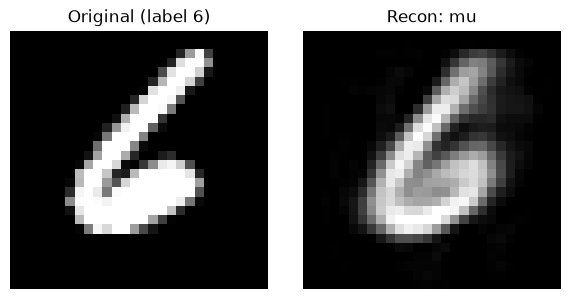

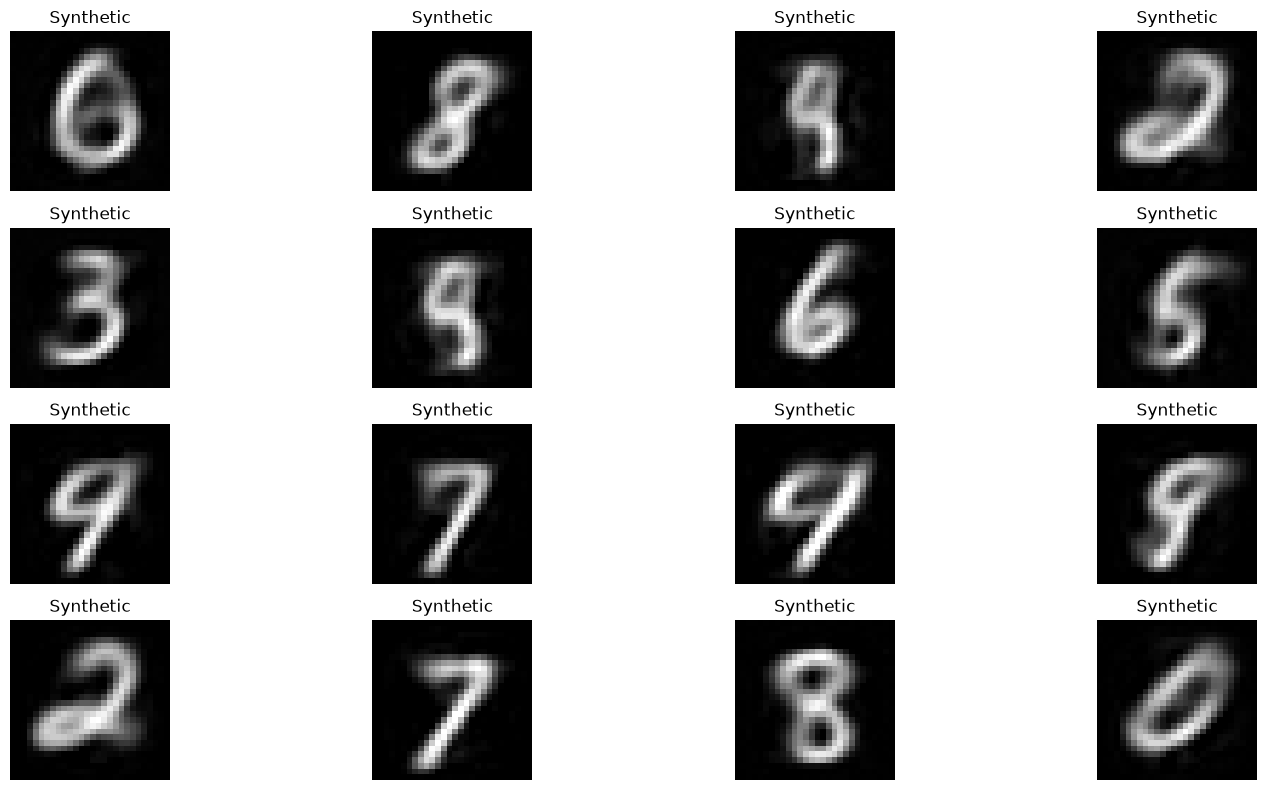

In [11]:
model.eval()

x_batch, labels_batch = next(iter(train_loader))
x_batch = x_batch[:bsize].to(device)

with torch.no_grad():
	x_recon, mu_decoder, mu_latent, chol = model(x_batch)

def show_mnist_image(ax, image, title):
	image = ((image.squeeze().cpu() + 1) / 2).clamp(0, 1)
	ax.imshow(image, cmap="gray")
	ax.set_title(title)
	ax.axis("off")

fig, axes = plt.subplots(1, 2, figsize=(6, 3))
show_mnist_image(axes[0], x_batch[0], f"Original (label {labels_batch[0].item()})")
show_mnist_image(axes[1], mu_decoder[0].view(-1, 1, 28,28), "Recon: mu")
plt.tight_layout()
plt.show()

n_samples = 16
with torch.no_grad():
	z = torch.randn(n_samples, model.latent_dim, device=device)
	synthetic = model.decoder(z).view(-1, 1, 28, 28)

fig, axes = plt.subplots(4, 4, figsize=(16, 8))
for ax, image in zip(axes.flat, synthetic):
	show_mnist_image(ax, image, "Synthetic")
plt.tight_layout()
plt.show()